# Projet oiseaux · 03 · Transfer learning : résultats et analyse

**But :** présenter les résultats du calcul fait sur carte graphique (RunPod, NVIDIA L40S) et les analyser.

- Étapes 4 et 5 : comparaison de 4 backbones pré-entraînés, gelés, par *linear probe*.
- Étape 6 : fine-tuning complet du meilleur (DINOv2 ViT-L).
- Étape 7 : score de validation, puis **une seule** évaluation sur le test.
- Étape 8 : analyse des erreurs, des quasi-doublons et des limites.

Ce notebook ne refait aucun calcul lourd : il relit les fichiers produits par `scripts/compare_backbones.py`, `scripts/finetune.py` et `scripts/evaluate.py` (dossier `outputs/`). Il s'exécute sur un portable sans carte graphique.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path(".")
OUT = ROOT / "outputs"
FT = OUT / "finetune_dinov2_l"
meta = pd.read_csv(ROOT / "metadata.csv")
CLASSES = json.loads((ROOT / "classes.json").read_text(encoding="utf-8"))
print(len(CLASSES), "espèces")

525 espèces


## 1. Étapes 4 et 5 : quel backbone comprend le mieux les oiseaux ?

Chaque backbone est **gelé** : on lui fait lire toutes les photos une fois, on garde son « résumé » de chaque photo (vecteur de caractéristiques), et on n'entraîne qu'une couche linéaire par-dessus. La différence de score vient donc uniquement de la qualité du backbone.

In [2]:
summary = pd.read_csv(OUT / "compare" / "summary.csv").sort_values("val_acc", ascending=False)
summary

,backbone,params_M,val_acc,val_top5,weight_decay,minutes
1,dinov2_l,303.2,0.9928,0.9992,0.1000,18.9
3,bioclip2,304.0,0.9912,0.9996,0.0001,8.3
2,eva02_l,303.3,0.9890,1.0000,0.0100,23.5
0,resnet18,11.2,0.9250,0.9863,0.1000,1.5


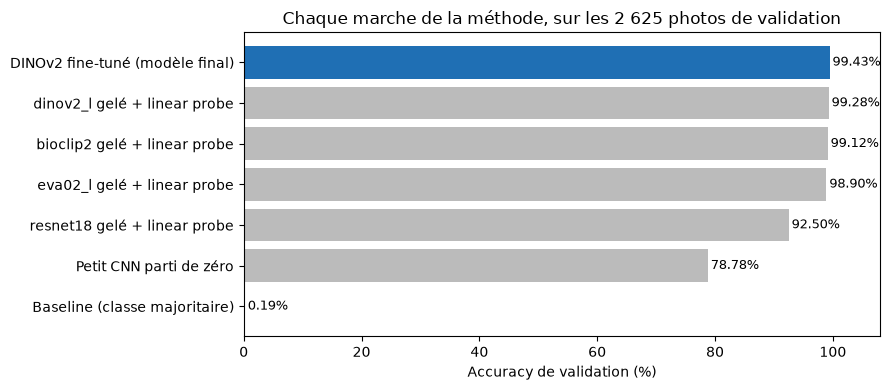

In [3]:
rows = [("Baseline (classe majoritaire)", 1 / 525), ("Petit CNN parti de zéro", 0.7878)]
rows += [(f"{b} gelé + linear probe", a) for b, a in zip(summary.backbone[::-1], summary.val_acc[::-1])]
rows += [("DINOv2 fine-tuné (modèle final)", 0.99429)]
names, accs = zip(*rows)
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#bbbbbb"] * (len(rows) - 1) + ["#1f6fb4"]
ax.barh(names, [a * 100 for a in accs], color=colors)
for y, a in enumerate(accs):
    ax.text(a * 100 + 0.5, y, f"{a:.2%}", va="center", fontsize=9)
ax.set_xlim(0, 108)
ax.set_xlabel("Accuracy de validation (%)")
ax.set_title("Chaque marche de la méthode, sur les 2 625 photos de validation")
plt.tight_layout()
plt.show()

**Lecture.**

- Le saut le plus important est le passage au **pré-entraînement** : ResNet18 gelé (92,5 %) fait déjà 14 points de mieux que notre petit CNN parti de zéro (78,8 %), sans changer un seul de ses poids.
- Les trois gros backbones (300 millions de paramètres) sont tous au-dessus de 98,9 %. DINOv2 arrive premier (99,28 %), devant BioCLIP 2 (99,12 %) et EVA-02 (98,90 %).
- **Attention** : la marge d'erreur à ce niveau est d'environ ± 0,3 point. Les trois gros modèles sont donc pratiquement à égalité. On garde DINOv2 parce que c'était la règle fixée à l'avance : le meilleur score de validation.

## 2. Étape 6 : le fine-tuning de DINOv2

On dégèle tout le réseau et on ajuste ses 304 millions de poids très doucement (AdamW, pas de 5e-5 en haut, layer-wise decay 0,85, warmup, cosinus, label smoothing, drop path, EMA), pendant 12 epochs de 8 min 30.

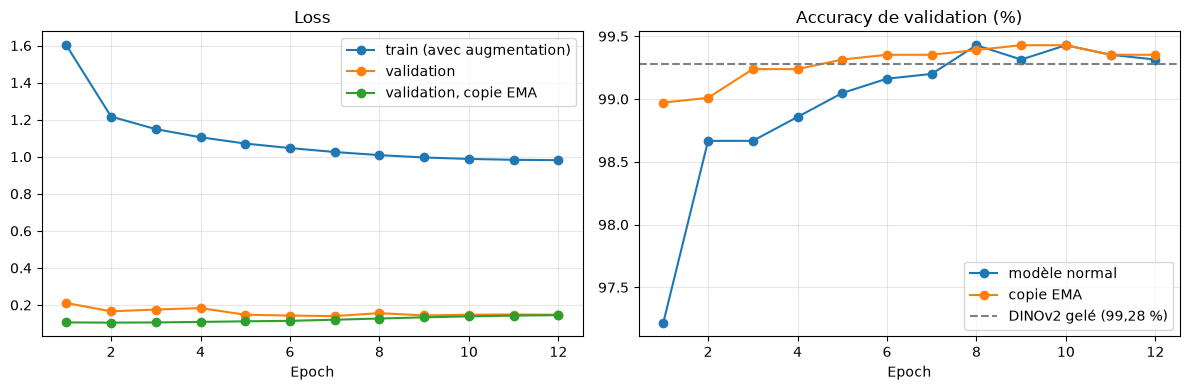

,epoch,train_loss,val_loss,val_acc,val_top5,ema_val_loss,ema_val_acc,ema_val_top5,minutes
0,1,1.6017,0.2108,0.9722,0.9973,0.1062,0.9897,0.9992,8.5531
1,2,1.2167,0.1661,0.9867,0.9992,0.1051,0.9901,1.0000,8.5437
2,3,1.1489,0.1755,0.9867,0.9992,0.1060,0.9924,0.9996,8.5453
3,4,1.1051,0.1837,0.9886,0.9996,0.1090,0.9924,1.0000,8.5434
4,5,1.0711,0.1477,0.9905,1.0000,0.1121,0.9931,1.0000,8.5438
5,6,1.0468,0.1433,0.9916,1.0000,0.1149,0.9935,1.0000,8.5454
6,7,1.0255,0.1403,0.9920,1.0000,0.1207,0.9935,1.0000,8.5272
7,8,1.0086,0.1564,0.9943,1.0000,0.1273,0.9939,1.0000,8.5377
8,9,0.9959,0.1437,0.9931,1.0000,0.1336,0.9943,1.0000,8.5329
9,10,0.9882,0.1477,0.9943,1.0000,0.1390,0.9943,1.0000,8.5196


In [4]:
hist = pd.read_csv(FT / "history.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.epoch, hist.train_loss, "o-", label="train (avec augmentation)")
axes[0].plot(hist.epoch, hist.val_loss, "o-", label="validation")
axes[0].plot(hist.epoch, hist.ema_val_loss, "o-", label="validation, copie EMA")
axes[0].set_title("Loss")
axes[1].plot(hist.epoch, hist.val_acc * 100, "o-", label="modèle normal")
axes[1].plot(hist.epoch, hist.ema_val_acc * 100, "o-", label="copie EMA")
axes[1].axhline(99.28, color="gray", ls="--", label="DINOv2 gelé (99,28 %)")
axes[1].set_title("Accuracy de validation (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
hist.round(4)

**Lecture des courbes.**

- **Epoch 1 : une « secousse ».** Le modèle normal tombe à 97,2 %, sous le modèle gelé. C'est attendu : on commence à modifier tout le réseau, avec le pas d'apprentissage au plus haut. La copie EMA (moyenne des poids dans le temps) encaisse cette secousse et reste vers 99 %.
- **Epochs 2 à 8 : remontée régulière**, jusqu'à 99,43 % à l'epoch 8 (15 erreurs sur 2 625).
- **Epochs 9 à 12 : plateau** entre 99,31 et 99,43 %. Le script a gardé automatiquement l'epoch 8.
- **Pas de sur-apprentissage grave** : la loss de validation du modèle normal reste stable. Celle de la copie EMA remonte doucement après l'epoch 2 alors que son accuracy monte : le modèle devient plus *sûr de lui* sur les quelques photos qu'il rate encore. C'est un signe à surveiller si on entraînait plus longtemps.
- **Gain du fine-tuning : + 0,15 point** (99,28 → 99,43 %), soit 4 erreurs de moins. C'est dans la marge d'erreur. Conclusion honnête : l'essentiel du travail est fait par le pré-entraînement ; le fine-tuning apporte une petite amélioration, pas une révolution.

## 3. Étape 7 : le score final

**Choix figés avant d'ouvrir le test** (fichier `outputs/finetune_dinov2_l/CHOIX_FIGE.txt`) : les poids de l'epoch 8, **sans TTA**. Sur la validation, la TTA (moyenne avec l'image en miroir) faisait 99,35 % contre 99,43 % sans : elle n'aide pas, on ne la garde pas.

Le test a ensuite été évalué **une seule fois** (fichier `TEST_DEJA_UTILISE.txt`).

In [5]:
def score(split):
    d = pd.read_csv(FT / f"predictions_{split}.csv")
    acc, n = d.correct.mean(), len(d)
    top5 = np.mean([v in t.split(" | ") for v, t in zip(d.vraie, d.top5)])
    return {"tas": split, "photos": n, "accuracy": f"{acc:.2%}", "marge (95 %)": f"± {1.96 * (acc * (1 - acc) / n) ** 0.5:.2%}",
            "top-5": f"{top5:.2%}", "erreurs": int((~d.correct).sum())}

pd.DataFrame([score("val"), score("test")])

,tas,photos,accuracy,marge (95 %),top-5,erreurs
0,val,2625,99.43%,± 0.29%,100.00%,15
1,test,2625,99.43%,± 0.29%,100.00%,15


**Le score officiel du modèle est 99,43 % ± 0,29 sur le test**, et la bonne espèce est toujours dans les 5 premières propositions (top-5 = 100 %).

Le score de test est **identique** à celui de validation. C'est rassurant : le modèle n'a pas été réglé « pour » la validation, il se comporte pareil sur des photos qu'il n'a jamais vues.

## 4. Étape 8 : les 15 erreurs du test, une par une

À gauche, la photo de test et sa vraie étiquette. À droite, une photo du train de l'espèce que le modèle a répondue, avec sa confiance.

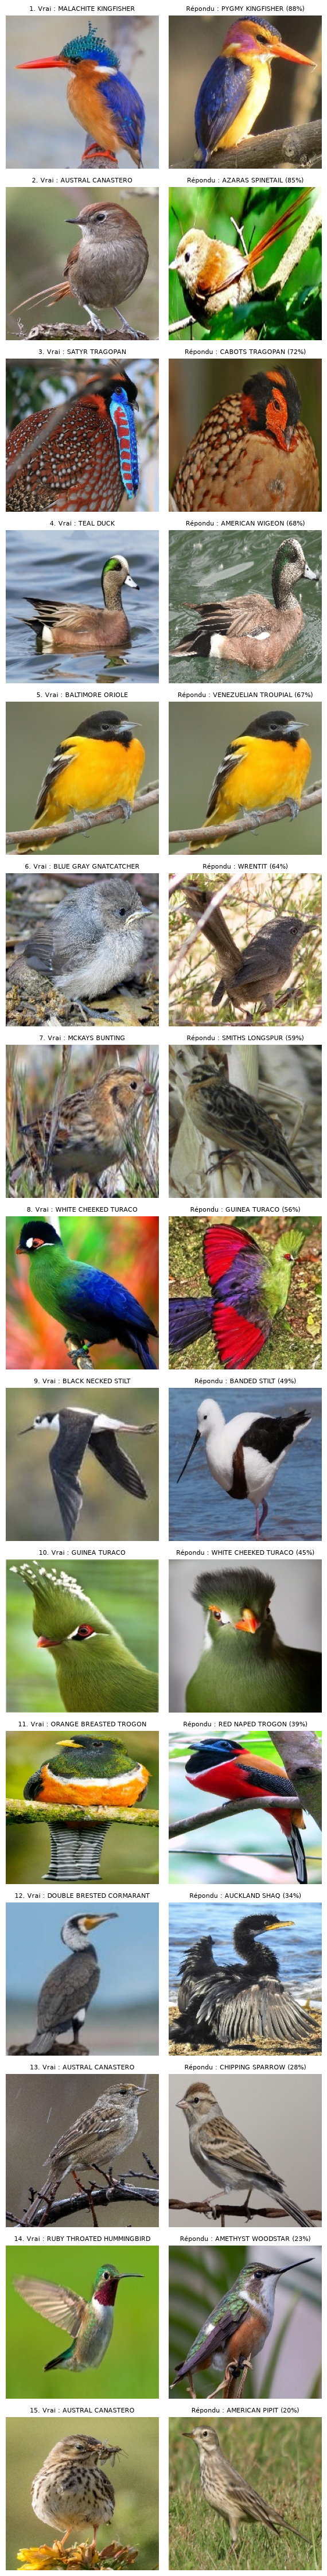

In [6]:
test = pd.read_csv(FT / "predictions_test.csv")
train = meta[meta.partition == "train"]
err = test[~test.correct].sort_values("confiance", ascending=False).reset_index(drop=True)
fig, axes = plt.subplots(len(err), 2, figsize=(6, 3 * len(err)))
for i, r in err.iterrows():
    example = train[train.espece == r.predite].iloc[0].chemin
    axes[i, 0].imshow(Image.open(ROOT / r.chemin))
    axes[i, 0].set_title(f"{i + 1}. Vrai : {r.vraie}", fontsize=8)
    axes[i, 1].imshow(Image.open(ROOT / example))
    axes[i, 1].set_title(f"Répondu : {r.predite} ({r.confiance:.0%})", fontsize=8)
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Classement des 15 erreurs** (fait en regardant chaque photo ; l'identification d'un oiseau sur photo par un non-spécialiste reste une estimation) :

| Type d'erreur | Erreurs (n° ci-dessus) | Nombre | Ce que ça veut dire |
|---|---|---|---|
| **Étiquette du dataset probablement fausse** | 4 (« TEAL DUCK » qui montre un canard d'Amérique, l'espèce répondue), 5 (« BALTIMORE ORIOLE » : **la même photo** est dans le train sous le nom VENEZUELIAN TROUPIAL), 7 (« MCKAYS BUNTING », un bruant blanc, alors que la photo montre un oiseau brun rayé proche du plectrophane répondu) | 3 | Le modèle a probablement raison, ou il a appris une erreur du dataset. Personne ne peut « réussir » ces photos. |
| **Classe mal constituée** | 2, 13, 15 (AUSTRAL CANASTERO) | 3 | 3 des 5 photos de test de cette espèce sont ratées. Ses photos de train mélangent des oiseaux d'allures très différentes : la classe elle-même est incohérente. |
| **Espèces très proches** | 1 (martins-pêcheurs), 3 (tragopans), 8 et 10 (deux touracos confondus dans les deux sens), 11 (trogons), 14 (colibris) | 6 | Des espèces voisines qui se distinguent par un petit détail. Des erreurs « honnêtes », que ferait aussi un amateur. |
| **Photo difficile** | 6 (un jeune encore duveteux), 9 (oiseau en vol, vu de dessous), 12 (cormoran au plumage inhabituel) | 3 | Une pose ou un âge peu représentés dans le train, qui contient surtout des adultes posés, de profil. |

**Conclusion :** environ **6 erreurs sur 15** (40 %) viennent du dataset lui-même (étiquettes fausses, classe incohérente), pas du modèle. Corrigées, le score serait proche de 99,7 %. Le plafond réel de ce dataset n'est pas 100 %.

Les 15 erreurs de **validation** racontent la même histoire. Trois sont des étiquettes probablement fausses :

- « APAPANE », qui montre un IIWI ;
- « TEAL DUCK », qui montre un colvert ;
- « EUROPEAN GOLDFINCH », qui montre un tarin.

Les autres sont surtout des espèces très proches. Par exemple, PURPLE FINCH est confondu 3 fois avec HOUSE FINCH. Ce sont deux roselins que même les ornithologues amateurs confondent.

**La classe TEAL DUCK apparaît deux fois** parmi les étiquettes fausses : une fois en validation, une fois en test. Elle mérite d'être nettoyée.

In [7]:
rec = pd.read_csv(FT / "recall_test.csv")
print("Espèces du test qui ne sont pas à 5/5 :")
rec[rec.recall < 1].assign(sur_5=lambda d: (d.recall * 5).round().astype(int))[["vraie", "sur_5"]]

Espèces du test qui ne sont pas à 5/5 :


,vraie,sur_5
0,AUSTRAL CANASTERO,2
1,BALTIMORE ORIOLE,4
2,TEAL DUCK,4
3,RUBY THROATED HUMMINGBIRD,4
4,SATYR TRAGOPAN,4
5,ORANGE BREASTED TROGON,4
6,MALACHITE KINGFISHER,4
7,MCKAYS BUNTING,4
8,GUINEA TURACO,4
9,DOUBLE BRESTED CORMARANT,4


## 5. Les quasi-doublons entre train et test (slide 79)

Le cours demande que des photos très proches (même objet, même séance) ne soient pas réparties entre le train et le test. Sinon le modèle peut « reconnaître de mémoire » au lieu de comprendre. Le dataset ne dit pas d'où vient chaque photo, donc on le vérifie autrement.

Pour chaque photo de test, on cherche la photo du train **la plus ressemblante**, avec les résumés de DINOv2 gelé. La ressemblance est mesurée par la *similarité cosinus* : 1 = identique, plus c'est bas, plus c'est différent.

In [8]:
tr = torch.from_numpy(np.load(OUT / "compare" / "features_dinov2_l_train.npy").astype(np.float32))
te = torch.from_numpy(np.load(OUT / "compare" / "features_dinov2_l_test.npy").astype(np.float32))
tr, te = torch.nn.functional.normalize(tr, dim=1), torch.nn.functional.normalize(te, dim=1)
best, idx = [], []
for k in range(0, len(te), 256):
    v, i = (te[k:k + 256] @ tr.T).max(1)
    best.append(v); idx.append(i)
test["sim"] = torch.cat(best).numpy()
test["jumeau"] = train.chemin.values[torch.cat(idx).numpy()]

rows = []
for th in (0.95, 0.97, 0.99):
    m = test.sim > th
    rows.append({"seuil": th, "photos de test concernées": f"{m.sum()} ({m.mean():.1%})",
                 "accuracy sur ces photos": f"{test[m].correct.mean():.2%}",
                 "accuracy sur les autres": f"{test[~m].correct.mean():.2%}"})
pd.DataFrame(rows)

,seuil,photos de test concernées,accuracy sur ces photos,accuracy sur les autres
0,0.95,836 (31.8%),99.40%,99.44%
1,0.97,453 (17.3%),98.90%,99.54%
2,0.99,131 (5.0%),96.95%,99.56%


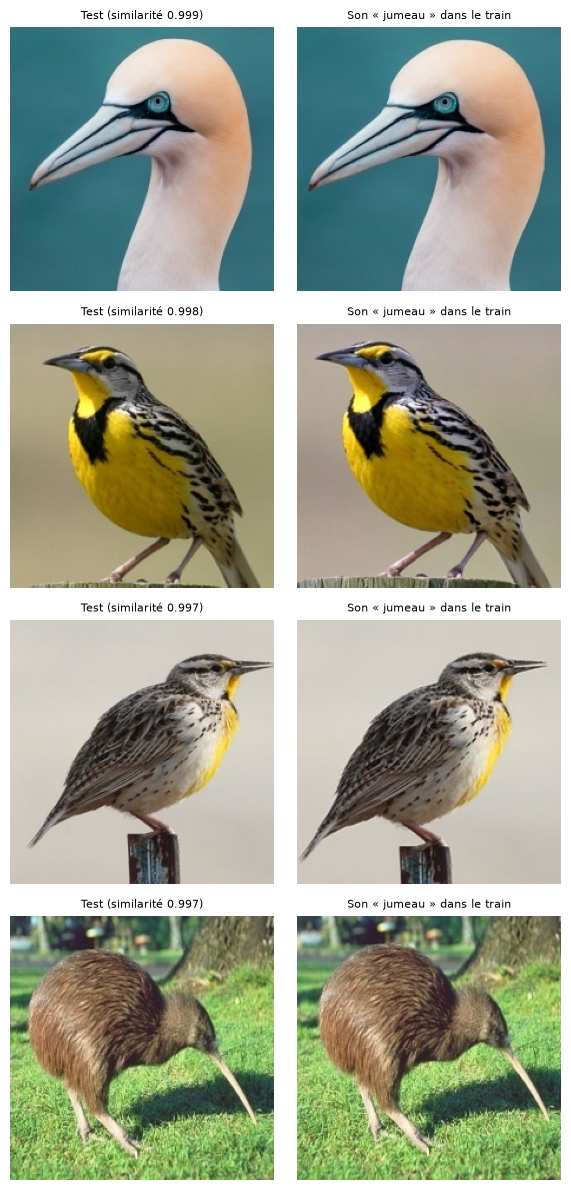

In [9]:
top = test.sort_values("sim", ascending=False).head(4).reset_index(drop=True)
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for i, r in top.iterrows():
    axes[i, 0].imshow(Image.open(ROOT / r.chemin)); axes[i, 0].set_title(f"Test (similarité {r.sim:.3f})", fontsize=8)
    axes[i, 1].imshow(Image.open(ROOT / r.jumeau)); axes[i, 1].set_title("Son « jumeau » dans le train", fontsize=8)
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Ce qu'on trouve.**

- **Il y a de vraies fuites.** Au-dessus de 0,99, les paires sont **la même photo**, simplement recadrée ou décalée de quelques pixels. Cela concerne 131 photos de test (5 %). Entre 0,97 et 0,99, on trouve un mélange : parfois la même photo, parfois une autre photo du même oiseau. Le dataset ne respecte donc pas la règle des groupes de la slide 79.
- **Mais ces fuites ne gonflent pas le score.** Sur les photos qui ont un « jumeau » dans le train, l'accuracy n'est pas meilleure, elle est même un peu plus basse. Sur toutes les autres photos, sans jumeau proche, elle reste à **99,5 %**. Le modèle ne réussit donc pas « de mémoire » : il réussit aussi bien sur des photos vraiment nouvelles.
- **Conclusion :** le score de 99,43 % est **crédible**, malgré les doublons. Si on refaisait le projet, on supprimerait ces doublons du test avant tout entraînement.

## 6. Le modèle sait-il quand il ne sait pas ?

Une bonne qualité pour un vrai outil : être **moins sûr de soi quand on se trompe**.

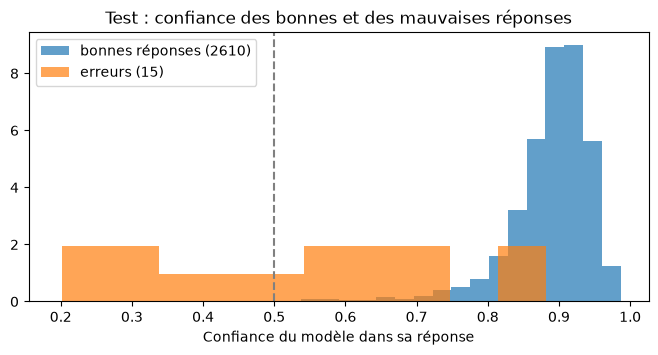

Réponses avec moins de 50 % de confiance : 20 (0.8%), dont 7 erreurs
Réponses avec au moins 50 % de confiance : 2605, accuracy 99.69%


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(test[test.correct].confiance, bins=30, alpha=0.7, label=f"bonnes réponses ({test.correct.sum()})", density=True)
ax.hist(test[~test.correct].confiance, bins=10, alpha=0.7, label=f"erreurs ({(~test.correct).sum()})", density=True)
ax.axvline(0.5, color="gray", ls="--")
ax.set_xlabel("Confiance du modèle dans sa réponse"); ax.legend(); ax.set_title("Test : confiance des bonnes et des mauvaises réponses")
plt.show()
low = test.confiance < 0.5
print(f"Réponses avec moins de 50 % de confiance : {low.sum()} ({low.mean():.1%}), dont {(~test[low].correct).sum()} erreurs")
print(f"Réponses avec au moins 50 % de confiance : {(~low).sum()}, accuracy {test[~low].correct.mean():.2%}")

**Lecture.**

- La confiance moyenne est d'environ 89 % sur les bonnes réponses, contre environ 53 % sur les erreurs.
- Près de la moitié des erreurs (7 sur 15) ont une confiance sous 50 %, contre très peu de bonnes réponses. Le programme `predict.py` affiche justement un avertissement « peu sûr » sous ce seuil.
- **Pourquoi même les bonnes réponses dépassent rarement 95 % ?** C'est un effet du *label smoothing* : on a appris au modèle à ne jamais être sûr à 100 %.

## 7. Le modèle en action

Le livrable : la fonction `predict` de `scripts/predict.py`, qui marche sans carte graphique. Le chargement prend environ une minute sur un portable, puis environ une seconde par photo.

Pour l'utiliser en ligne de commande : `python scripts/predict.py --ckpt outputs/finetune_dinov2_l/best.pt ma_photo.jpg`

C:\Users\Lucas\Desktop\BirdsAI\AI_2600\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modèle dinov2_l, epoch 8, 304 M paramètres


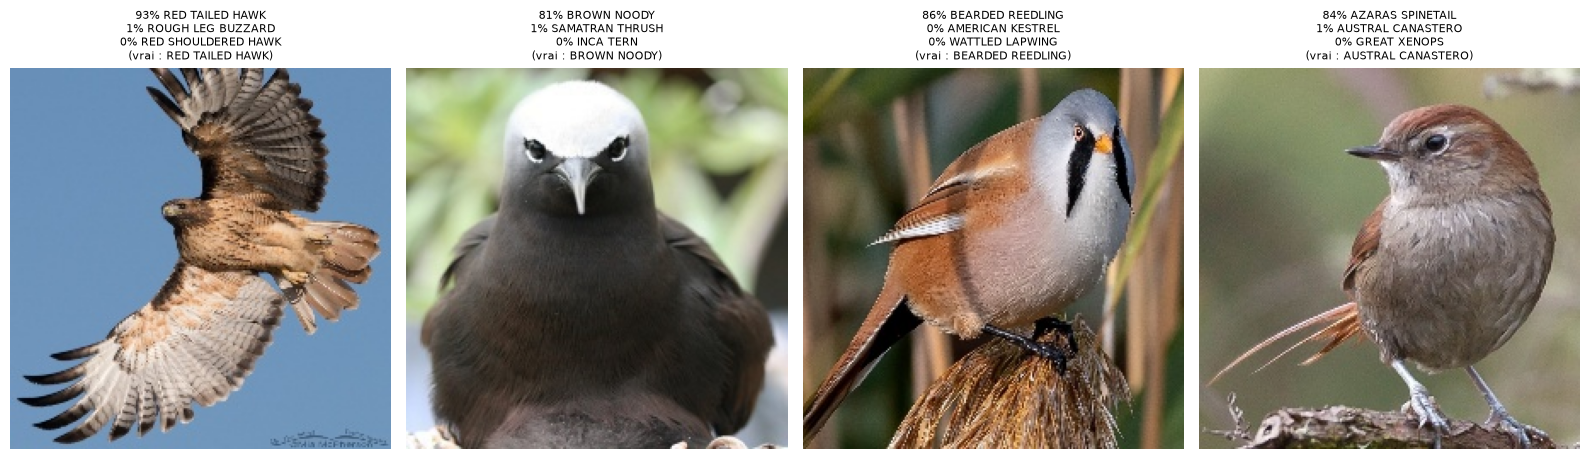

In [11]:
import sys
sys.path.insert(0, "scripts")
from common import load_classifier
from predict import predict

model, ck = load_classifier(FT / "best.pt")
print(f"Modèle {ck['model']}, epoch {ck['epoch']}, {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M paramètres")
exemples = test.sample(3, random_state=7).chemin.tolist() + [err.chemin[1]]
fig, axes = plt.subplots(1, len(exemples), figsize=(16, 4.5))
for ax, path in zip(axes, exemples):
    im = Image.open(ROOT / path)
    top = predict(model, ck, im, k=3)
    ax.imshow(im); ax.axis("off")
    ax.set_title("\n".join(f"{p:.0%} {n}" for n, p in top) + f"\n(vrai : {Path(path).parent.name})", fontsize=8)
plt.tight_layout()
plt.show()

## 8. Bilan, limites et prochaine expérience

| Étape | Modèle | Validation | Test |
|---|---|---|---|
| 2 | Baseline (classe majoritaire) | 0,19 % | — |
| 3 | Petit CNN parti de zéro (64 × 64, CPU) | 78,8 % ± 1,6 | — |
| 4-5 | ResNet18 gelé + linear probe | 92,50 % | — |
| 4-5 | EVA-02 Large gelé + linear probe | 98,90 % | — |
| 4-5 | BioCLIP 2 gelé + linear probe | 99,12 % | — |
| 4-5 | DINOv2 ViT-L gelé + linear probe | 99,28 % | — |
| 6-7 | **DINOv2 ViT-L fine-tuné** | **99,43 % ± 0,29** | **99,43 % ± 0,29** |

**Ce qu'on retient.**

1. Le **pré-entraînement** fait presque tout. Passer de zéro à un modèle pré-entraîné gelé fait gagner 20 points. Le fine-tuning n'en ajoute que 0,15.
2. Les erreurs restantes viennent pour environ 40 % du **dataset** (étiquettes fausses, une classe incohérente), et pour le reste d'espèces très proches ou de photos inhabituelles.
3. Le dataset contient des **doublons entre train et test**, mais ils ne gonflent pas le score.

**Limites.**

- **Des photos « de catalogue ».** Un oiseau seul, centré, net, souvent un mâle adulte. Sur des photos de la vraie vie (oiseau lointain, flou, jeune, femelle, plusieurs oiseaux), le score sera plus bas. Il reste à le mesurer sur nos propres photos.
- **525 espèces seulement.** Un oiseau d'une autre espèce recevra quand même un des 525 noms, avec en général une confiance basse.
- **Le pré-entraînement de DINOv2 a peut-être vu certaines de ces images**, car les deux viennent d'Internet. On ne peut pas le vérifier.
- **La marge d'erreur (± 0,3 point) empêche de départager** les trois meilleurs backbones.

**Prochaine expérience (une modification justifiée, comme le demande le cours).** Nettoyer le dataset, puis réentraîner et réévaluer sur un nouveau test indépendant :

- retirer les quasi-doublons entre train et test ;
- corriger les étiquettes fausses repérées (TEAL DUCK, BALTIMORE ORIOLE, MCKAYS BUNTING, APAPANE, EUROPEAN GOLDFINCH) ;
- vérifier la classe AUSTRAL CANASTERO.

Ensuite, mesurer le modèle sur des photos prises par nous-mêmes.